In [157]:
import http.client
import time
import urllib.error

import matplotlib as mpl
import matplotlib.colorizer
import matplotlib.pyplot as plt
import numpy as np
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import Table
from astropy.utils.data import conf
from astropy.visualization import AsinhStretch, ImageNormalize
from astropy.wcs import WCS
from astroquery.ipac.irsa import Irsa
from firefly_client import FireflyClient

# The time it takes to read SPHEREx files can exceed
# astropy's default timeout limit. Increase it.
conf.remote_timeout = 120

In [158]:
ra_deg = 304.693508808
dec_deg = 42.4436872991

coord = SkyCoord(ra_deg, dec_deg, unit="deg")
search_radius = 1 * u.arcsec

display(coord, u.__dict__, search_radius)

<SkyCoord (ICRS): (ra, dec) in deg
    (304.69350881, 42.4436873)>

{'__name__': 'astropy.units',
 '__doc__': '\nThis subpackage contains classes and functions for defining and converting\nbetween different physical units, as well as the units themselves.\n\nThis code is adapted from the `pynbody\n<https://github.com/pynbody/pynbody>`_ units module written by Andrew\nPontzen, who has granted the Astropy project permission to use the\ncode under a BSD license.\n',
 '__package__': 'astropy.units',
 '__loader__': <_frozen_importlib_external.SourceFileLoader at 0x7f1d34b12510>,
 '__spec__': ModuleSpec(name='astropy.units', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7f1d34b12510>, origin='/home/juand/Documents/vscode/OwnProjects/NasaSpaceApps2026/apps/server/.venv/lib/python3.14/site-packages/astropy/units/__init__.py', submodule_search_locations=['/home/juand/Documents/vscode/OwnProjects/NasaSpaceApps2026/apps/server/.venv/lib/python3.14/site-packages/astropy/units']),
 '__path__': ['/home/juand/Documents/vscode/OwnProjects/NasaSpaceAp

<Quantity 1. arcsec>

In [159]:
Irsa.list_collections(servicetype="SIA", filter="spherex")

collection
object
spherex_qr2
spherex_qr2_deep
spherex_qr3
spherex_qr3_deep


In [160]:
t0 = time.perf_counter()
results: Table = Irsa.query_sia(pos=(coord, search_radius), collection="spherex_qr2")
tf = time.perf_counter()
print(f"Query time: {tf - t0:.2f} seconds")

/home/juand/Documents/vscode/OwnProjects/NasaSpaceApps2026/apps/server/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:2611: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*args, out=...)


Query time: 1.76 seconds


In [161]:
df_pandas = results.to_pandas()
display(results.info, df_pandas.head())

<Table length=415>
          name           dtype   unit  format                                 description                                 n_bad
----------------------- ------- ------ ------ --------------------------------------------------------------------------- -----
                   s_ra float64    deg                                   Central Spatial Position in ICRS Right ascension     0
                  s_dec float64    deg                                       Central Spatial Position in ICRS Declination     0
          facility_name  object                                             Name of telescope used to acquire observation     0
        instrument_name  object                                            Name of instrument used to acquire observation     0
    dataproduct_subtype  object                        Product type (e.g. science, calibration, auxiliary, preview, info)     0
            calib_level   int16                                  Calibration level of

,s_ra,s_dec,facility_name,instrument_name,dataproduct_subtype,calib_level,dataproduct_type,energy_bandpassname,energy_emband,obs_id,...,t_resolution,t_xel,obs_publisher_did,s_fov,em_xel,pol_states,pol_xel,cloud_access,o_ucd,upload_row_id
0,302.842981,43.527456,SPHEREx,SPHEREx,science,2,image,SPHEREx-D2,Infrared,2025W43_1A_0516_1,...,NaN,<NA>,ivo://irsa.ipac/spherex_qr2?2025W43_1A_0516_1/D2,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
1,302.848614,43.510312,SPHEREx,SPHEREx,science,2,image,SPHEREx-D5,Infrared,2025W43_1A_0516_1,...,NaN,<NA>,ivo://irsa.ipac/spherex_qr2?2025W43_1A_0516_1/D5,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
2,302.523161,42.313373,SPHEREx,SPHEREx,science,2,image,SPHEREx-D3,Infrared,2026W20_2A_0058_4,...,NaN,<NA>,ivo://irsa.ipac/spherex_qr2?2026W20_2A_0058_4/D3,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
3,302.508006,42.329546,SPHEREx,SPHEREx,science,2,image,SPHEREx-D6,Infrared,2026W20_2A_0058_4,...,NaN,<NA>,ivo://irsa.ipac/spherex_qr2?2026W20_2A_0058_4/D6,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
4,303.512013,42.806981,SPHEREx,SPHEREx,science,2,image,SPHEREx-D5,Infrared,2026W20_2A_0191_4,...,NaN,<NA>,ivo://irsa.ipac/spherex_qr2?2026W20_2A_0191_4/D5,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1


In [162]:
df_pandas["target_name"].unique()

<StringArray>
['SPS_100869',  'SPS_29549',  'SPS_29532',  'SPS_28539',  'SPS_29552',
  'SPS_29547',  'SPS_29530',  'SPS_29548',  'SPS_29550',  'SPS_29531',
 ...
  'SPS_99849',  'SPS_28491', 'SPS_100887', 'SPS_100900',  'SPS_99838',
  'SPS_99820',  'SPS_28505',  'SPS_99836',  'SPS_99870',  'SPS_99855']
Length: 148, dtype: str

In [166]:
print(df_pandas.shape)
df_pandas[["obs_id", "energy_bandpassname"]].groupby(
    "energy_bandpassname"
).count().sort_values(by="obs_id", ascending=False)

(415, 51)


,obs_id
energy_bandpassname,
SPHEREx-D6,86
SPHEREx-D1,81
SPHEREx-D4,71
SPHEREx-D3,65
SPHEREx-D2,56
SPHEREx-D5,56


In [15]:
# And qr3? Is the same Table?
t0 = time.perf_counter()
results_qr3: Table = Irsa.query_sia(
    pos=(coord, search_radius), collection="spherex_qr3"
)
tf = time.perf_counter()
print(f"Query time: {tf - t0:.2f} seconds")

df_pandas_qr3 = results_qr3.to_pandas()
display(results_qr3.info, df_pandas_qr3.head())

/home/juand/Documents/vscode/OwnProjects/NasaSpaceApps2026/apps/server/.venv/lib/python3.14/site-packages/numpy/lib/_function_base_impl.py:2611: RuntimeWarning: invalid value encountered in do_format (vectorized)
  outputs = ufunc(*args, out=...)


Query time: 0.65 seconds


<Table length=0>
          name           dtype   unit  format                                 description                                
----------------------- ------- ------ ------ ---------------------------------------------------------------------------
                   s_ra float64    deg                                   Central Spatial Position in ICRS Right ascension
                  s_dec float64    deg                                       Central Spatial Position in ICRS Declination
          facility_name  object                                             Name of telescope used to acquire observation
        instrument_name  object                                            Name of instrument used to acquire observation
    dataproduct_subtype  object                        Product type (e.g. science, calibration, auxiliary, preview, info)
            calib_level   int16                                  Calibration level of the observation: in {0, 1, 2, 3, 4}
       

,s_ra,s_dec,facility_name,instrument_name,dataproduct_subtype,calib_level,dataproduct_type,energy_bandpassname,energy_emband,obs_id,...,t_resolution,t_xel,obs_publisher_did,s_fov,em_xel,pol_states,pol_xel,cloud_access,o_ucd,upload_row_id


## Using only one `.fits` file

In [167]:
spectral_image_url = results["access_url"][0]
print(f"Spectral image URL: {spectral_image_url}")

Spectral image URL: https://irsa.ipac.caltech.edu/ibe/data/spherex/qr2/level2/2025W43_1A/l2b-v20-2025-299/2/level2_2025W43_1A_0516_1D2_spx_l2b-v20-2025-299.fits


In [168]:
# Max number of times to retry HTTP errors.
max_retries = 3
for attempt in range(max_retries):
    try:
        # Load the data, reading every extension into memory so that
        # hdulist stays usable after the file is closed.
        t0 = time.perf_counter()
        with fits.open(spectral_image_url, memmap=False, cache=False) as hdulist:
            tf = time.perf_counter()
            for hdu in hdulist:
                hdu.data  # Force reading the data into memory
            print(f"Time to open FITS file: {tf - t0:.4f} seconds")
        break
    except (TimeoutError, urllib.error.HTTPError, http.client.IncompleteRead) as e:
        print(f"Attempt {attempt + 1} of {max_retries} failed with error: {e}")
        if attempt == max_retries - 1:
            raise
        time.sleep(10 * (attempt + 1))

Time to open FITS file: 51.7367 seconds


In [169]:
hdulist.info()
print(f"Number of extensions: {len(hdulist)}")

for i, hdu in enumerate(hdulist):
    print(
        f"Extension {i}: {hdu.name}, type: {type(hdu)}, shape: {hdu.data.shape if hdu.data is not None else 'None'}"
    )

Filename: /tmp/astropy-download-374855-u35t4xe4
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       237   (2040, 2040)   float32   
  2  FLAGS         1 ImageHDU       146   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       119   (2040, 2040)   float32   
  5  PSF           1 ImageHDU       509   (101, 101, 121)   float32   
  6  WCS-WAVE      1 BinTableHDU     18   1R x 3C   ['11J', '11J', '242E']   
Number of extensions: 7
Extension 0: PRIMARY, type: <class 'astropy.io.fits.hdu.image.PrimaryHDU'>, shape: None
Extension 1: IMAGE, type: <class 'astropy.io.fits.hdu.image.ImageHDU'>, shape: (2040, 2040)
Extension 2: FLAGS, type: <class 'astropy.io.fits.hdu.image.ImageHDU'>, shape: (2040, 2040)
Extension 3: VARIANCE, type: <class 'astropy.io.fits.hdu.image.ImageHDU'>, shape: (2040, 2040)
Extension 4: ZODI, type: <cla

In [170]:
hdulist[0].header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                    8 / array data type                                
NAXIS   =                    0 / number of array dimensions                     
EXTEND  =                    T                                                  
VERSION = '6.4+psffix1'        / SSDC Pipelines software version                

XTENSION= 'IMAGE   '           / Image extension                                
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 2040                                                  
NAXIS2  =                 2040                                                  
PCOUNT  =                    0 / number of parameters                           
GCOUNT  =                    1 / number of groups                               
EXTNAME = 'IMAGE   '           / extension name                                 
EXTTYPE = 'IMAGE   '           / Extension supports mask overlay                
BUNIT   = 'MJy / sr'           / Unit of pixel value                            
DETECTOR=                    2 / 1-3: SWIR, 4-6: MWIR                           
OBSID   = '2025W43_1A_0516_1'  / Observation ID                                 
EXPIDN  =      2025431010516

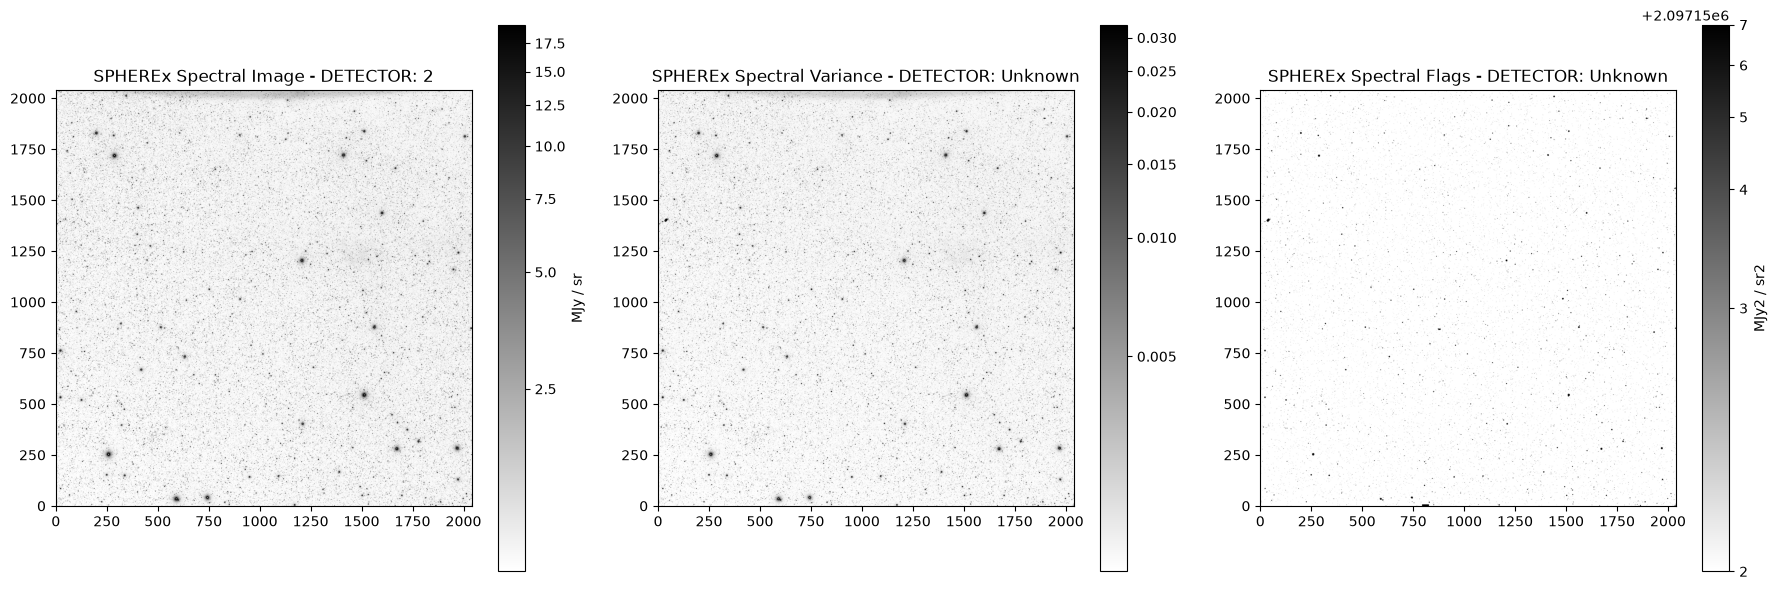

In [171]:
display(hdulist[1].header)

image = hdulist["IMAGE"].data.astype(float)
variance = hdulist["VARIANCE"].data
flags = hdulist["FLAGS"].data

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, (ax, data, title) in enumerate(
    zip(axes.flatten(), [image, variance, flags], ["Image", "Variance", "Flags"]),
    start=1,
):
    headers = hdulist[i].header

    # Identificar valores válidos
    valid = np.isfinite(data)

    # Obtener límites robustos
    vmin, vmax = np.nanpercentile(data[valid], [1, 99.5])

    # Normalización para imágenes astronómicas
    norm = ImageNormalize(vmin=vmin, vmax=vmax, stretch=AsinhStretch())
    cmap = plt.get_cmap("gray_r")
    colorizer = mpl.colorizer.Colorizer(norm=norm, cmap=cmap)

    ax.imshow(data, origin="lower", cmap=cmap, norm=norm)
    ax.set(
        title=f"SPHEREx Spectral {title} - DETECTOR: {headers.get('DETECTOR', 'Unknown')}",
        # xlabel="X pixel",
        # ylabel="Y pixel",
    )
    fig.colorbar(
        mpl.colorizer.ColorizingArtist(colorizer),
        ax=ax,
        label=headers.get("BUNIT", "Unknown Unit"),
    )

    # plt.colorbar(label="MJy/sr")
    # plt.title(f"SPHEREx Spectral {title} - DETECTOR: {hdulist[1].header['DETECTOR']}")
    # plt.xlabel("X pixel")
    # plt.ylabel("Y pixel")

fig.tight_layout()
plt.show()

In [135]:
image.dtype

dtype('float64')

In [90]:
fc = FireflyClient.make_client(url="https://irsa.ipac.caltech.edu/irsaviewer")

fc.reinit_viewer()

{'success': True}

In [95]:
fc.show_fits_image(
    file_input=spectral_image_url, plot_id="spectral_image", Title="Spectral Image"
)

{'success': True}

### WCS

In [46]:
hdulist[1].header["WCSNAME*"]

WCSNAMEA= '0-based active pixel coordinates' / Coordinate system title          
WCSNAMEW= 'Approximated per-pixel wavelength and bandwidth' / WCS label         

In [45]:
wcs = WCS(hdulist[1].header)
wcs

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN-SIP' 'DEC--TAN-SIP'
CUNIT : 'deg' 'deg'
CRVAL : 302.844429816 43.5254862169
CRPIX : 1020.5 1020.5
PC1_1 PC1_2  : 0.00153702368298 0.00073583356182
PC2_1 PC2_2  : 0.00073404154569 -0.00154006537788
CDELT : 1.0 1.0
NAXIS : 2040  2040

In [47]:
ra, dec = wcs.wcs.crval
x, y = wcs.world_to_pixel(SkyCoord(ra=ra, dec=dec, unit="deg"))
print(ra, dec, x, y)

302.844429816 43.5254862169 1019.557455641915 1020.8065053475879


In [50]:
# Load the Spectral WCS from the header.
# Note that we need to provide a reference to HDU List, which contains a lookup table.
spectral_wcs = WCS(header=hdulist["IMAGE"].header, fobj=hdulist, key="W")

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]


In [51]:
# SIP distortions must be turned off for the spectral WCS.
spectral_wcs.sip = None

In [52]:
# The standard Astropy methods for converting pixel coordinates to world coordinates can also be used to obtain spectral coordinates.
# Take the pixel coordinates that we determined for the image center and resolve them to the wavelength and bandwidth for that pixel
wl, bw = spectral_wcs.pixel_to_world(x, y)
wl, bw

(<SpectralCoord 1.33718249 um>, <Quantity 0.03226627 um>)

In [53]:
# Read in the spectral image data.
spectral_image = hdulist["IMAGE"]
spectral_image_data = spectral_image.data

# Get arrays of pixel coordinates for the image.
(y, x) = np.indices(spectral_image.shape)

# Use the spectral WCS to convert these pixel coordinates to spectral coordinates.
spectral_coords = spectral_wcs.pixel_to_world(x, y)

# Break out the two spectral coordinates (wavelength and bandwidth) from the spectral coordinates, and print the results.
wavelength, bandwidth = spectral_coords
print("Wavelength: \n", wavelength)
print("Bandwidth: \n", bandwidth)

Wavelength: 
 [[1.66769683 1.66766461 1.66763238 ... 1.66739935 1.66742811 1.66745687]
 [1.66736472 1.6673325  1.66730029 ... 1.66707073 1.6670995  1.66712826]
 [1.66703261 1.6670004  1.66696819 ... 1.66674211 1.66677089 1.66679966]
 ...
 [1.10108413 1.10105606 1.10102799 ... 1.10102928 1.10105493 1.10108059]
 [1.10086162 1.10083353 1.10080544 ... 1.10080342 1.10082907 1.10085472]
 [1.1006391  1.100611   1.1005829  ... 1.10057757 1.10060321 1.10062885]] um
Bandwidth: 
 [[0.03979334 0.03979459 0.03979584 ... 0.0396945  0.03969552 0.03969654]
 [0.03978855 0.03978979 0.03979103 ... 0.03968965 0.03969068 0.0396917 ]
 [0.03978375 0.03978499 0.03978622 ... 0.03968479 0.03968583 0.03968686]
 ...
 [0.02552863 0.02552833 0.02552804 ... 0.02604323 0.02604796 0.0260527 ]
 [0.02551791 0.02551762 0.02551734 ... 0.02603482 0.02603957 0.02604432]
 [0.02550719 0.02550692 0.02550664 ... 0.02602641 0.02603118 0.02603594]] um


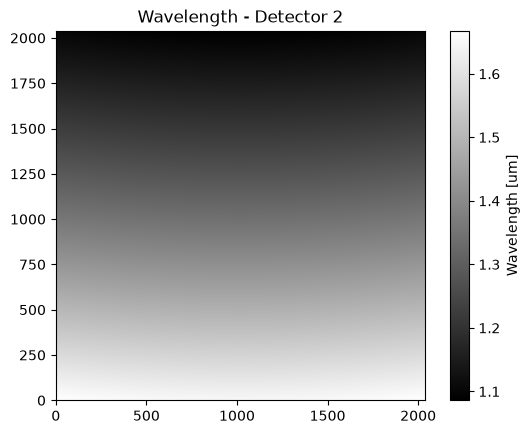

In [54]:
# Plot the wavelength as a greyscale color map across the image pixels.
plt.imshow(wavelength.value, origin="lower", cmap="gray")
plt.colorbar(label=f"Wavelength [{wavelength.unit}]")

detector = hdulist["IMAGE"].header["DETECTOR"]
plt.title(f"Wavelength - Detector {detector}")
plt.show()